# Project Machine Learning — Probabilistic Temperature Forecasting

Project ini menggunakan dataset probabilistic-forecasting-i-temperature untuk membuat model Machine Learning yang dapat memprediksi suhu (Temperature).

Metode yang digunakan adalah time-series regression dan probabilistic forecasting, yaitu memprediksi suhu berdasarkan data yang tersedia dengan menggunakan beberapa nilai kuantil.

Tahapan pengerjaan meliputi membaca dan memahami data, membersihkan data, melakukan eksplorasi dan visualisasi, menyiapkan fitur, membagi data, membuat model, mengevaluasi hasil prediksi, hingga menghasilkan file submission.

Sebelum menjalankan notebook, pastikan file train.csv, test.csv, dan sample_submission.csv sudah berada dalam satu folder dengan notebook. File train_and_Public.csv tidak digunakan sebagai pengganti train.csv karena pengerjaan ini mengikuti pasangan file training, testing, dan template submission yang telah disediakan.

## 1. Import library

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

## 2. Data loading

In [2]:
train = pd.read_csv("train.csv")
test = pd.read_csv("test.csv")
sample_submission = pd.read_csv("sample_submission.csv")

print("Ukuran train:", train.shape)
print("Ukuran test:", test.shape)
print("Ukuran sample_submission:", sample_submission.shape)

display(train.head())
display(test.head())
display(sample_submission.head())

Ukuran train: (64320, 9)
Ukuran test: (5360, 8)
Ukuran sample_submission: (5360, 22)


,id,date,feature_AA,feature_AB,feature_BA,feature_BB,feature_CA,feature_CB,Temperature
0,0,2016-07-01 00:00:00,5.827,2.009,1.599,0.462,4.203,1.340,30.531000
1,1,2016-07-01 00:15:00,5.760,2.076,1.492,0.426,4.264,1.401,30.459999
2,2,2016-07-01 00:30:00,5.760,1.942,1.492,0.391,4.234,1.310,30.038000
3,3,2016-07-01 00:45:00,5.760,1.942,1.492,0.426,4.234,1.310,27.013000
4,4,2016-07-01 01:00:00,5.693,2.076,1.492,0.426,4.142,1.371,27.787001


,id,date,feature_AA,feature_AB,feature_BA,feature_BB,feature_CA,feature_CB
0,64320,2018-05-02 00:00:00,14.133,2.076,9.346,-0.036,4.538,1.279
1,64321,2018-05-02 00:15:00,12.123,1.541,7.818,-0.746,4.538,1.249
2,64322,2018-05-02 00:30:00,12.525,1.741,8.209,-0.284,4.477,1.279
3,64323,2018-05-02 00:45:00,12.324,1.942,7.747,0.249,4.630,1.371
4,64324,2018-05-02 01:00:00,14.602,1.407,9.630,-0.320,4.477,1.310


,id,0.025,0.05,0.10,0.15,0.20,0.25,0.30,0.35,0.40,...,0.55,0.60,0.65,0.70,0.75,0.80,0.85,0.90,0.95,0.975
0,64320,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,64321,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,64322,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,64323,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,64324,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


## 3. Memahami data

In [3]:
print("Informasi train:")
train.info()

print("\nStatistik deskriptif:")
display(train.describe(include="all").T)

print("\nJumlah missing value pada train:")
display(train.isnull().sum().sort_values(ascending=False))

print("\nJumlah baris duplikat:", train.duplicated().sum())
print("\nKolom train:", train.columns.tolist())

Informasi train:
<class 'pandas.DataFrame'>
RangeIndex: 64320 entries, 0 to 64319
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   id           64320 non-null  int64  
 1   date         64320 non-null  str    
 2   feature_AA   64320 non-null  float64
 3   feature_AB   64320 non-null  float64
 4   feature_BA   64320 non-null  float64
 5   feature_BB   64320 non-null  float64
 6   feature_CA   64320 non-null  float64
 7   feature_CB   64320 non-null  float64
 8   Temperature  64320 non-null  float64
dtypes: float64(7), int64(1), str(1)
memory usage: 4.4 MB

Statistik deskriptif:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
id,64320.0,NaN,NaN,NaN,32159.5,18567.728994,0.0,16079.75,32159.5,48239.25,64319.0
date,64320,64320,2016-07-01 00:00:00,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
feature_AA,64320.0,NaN,NaN,NaN,7.522545,6.914888,-21.568001,5.961,8.841,11.721,24.18
feature_AB,64320.0,NaN,NaN,NaN,2.142897,2.023449,-5.693,0.67,2.076,3.55,10.315
feature_BA,64320.0,NaN,NaN,NaN,4.478698,6.669074,-23.986,3.553,6.041,8.635,18.087
feature_BB,64320.0,NaN,NaN,NaN,0.820356,1.818778,-6.041,-0.391,0.853,2.132,7.853
feature_CA,64320.0,NaN,NaN,NaN,3.042537,1.1697,-1.188,2.284,2.802,3.594,8.498
feature_CB,64320.0,NaN,NaN,NaN,0.819362,0.602287,-1.371,0.64,0.944,1.157,3.046
Temperature,64320.0,NaN,NaN,NaN,13.61043,8.827735,-4.221,6.753,11.959,18.712,46.007



Jumlah missing value pada train:


id             0
date           0
feature_AA     0
feature_AB     0
feature_BA     0
feature_BB     0
feature_CA     0
feature_CB     0
Temperature    0
dtype: int64


Jumlah baris duplikat: 0

Kolom train: ['id', 'date', 'feature_AA', 'feature_AB', 'feature_BA', 'feature_BB', 'feature_CA', 'feature_CB', 'Temperature']


## 4. Data cleaning

Pada tahap ini, dilakukan pemeriksaan terhadap data untuk mengetahui apakah terdapat nilai kosong (missing value) pada setiap kolom. Kolom yang memiliki banyak nilai kosong perlu diperiksa terlebih dahulu sebelum menentukan apakah perlu dihapus atau tetap digunakan.

Kolom id digunakan sebagai identitas setiap baris, sedangkan kolom date menunjukkan waktu pengambilan data. Oleh karena itu, kedua kolom tersebut perlu dibedakan dari kolom sensor yang digunakan dalam proses analisis.

Selain itu, nilai yang terlalu tinggi atau rendah (outlier) tidak langsung dihapus karena nilai tersebut belum tentu merupakan kesalahan data. Pemeriksaan dilakukan terlebih dahulu agar informasi penting dari data tetap dapat digunakan dalam proses pemodelan.

In [4]:
# Konversi kolom waktu
train["date"] = pd.to_datetime(train["date"], errors="coerce")
test["date"] = pd.to_datetime(test["date"], errors="coerce")

print("Missing value train sebelum cleaning:")
display(train.isnull().sum())

print("Missing value test sebelum cleaning:")
display(test.isnull().sum())

print("Duplikat train:", train.duplicated().sum())
print("Tanggal train tidak valid:", train["date"].isna().sum())
print("Tanggal test tidak valid:", test["date"].isna().sum())

Missing value train sebelum cleaning:


id             0
date           0
feature_AA     0
feature_AB     0
feature_BA     0
feature_BB     0
feature_CA     0
feature_CB     0
Temperature    0
dtype: int64

Missing value test sebelum cleaning:


id            0
date          0
feature_AA    0
feature_AB    0
feature_BA    0
feature_BB    0
feature_CA    0
feature_CB    0
dtype: int64

Duplikat train: 0
Tanggal train tidak valid: 0
Tanggal test tidak valid: 0


In [5]:
# Buang baris train yang target atau tanggalnya tidak valid
train = train.dropna(subset=["Temperature", "date"]).drop_duplicates().copy()
test = test.copy()

# Pastikan target berbentuk numerik
train["Temperature"] = pd.to_numeric(train["Temperature"], errors="coerce")
train = train.dropna(subset=["Temperature"]).copy()

print("Ukuran train setelah cleaning:", train.shape)

Ukuran train setelah cleaning: (64320, 9)


## 5. Exploratory Data Analysis (EDA)

EDA digunakan untuk memahami distribusi target, pola waktu, dan hubungan antarfitur sebelum modelling.

,Temperature
count,64320.000000
mean,13.610430
std,8.827735
min,-4.221000
25%,6.753000
50%,11.959000
75%,18.712000
max,46.007000


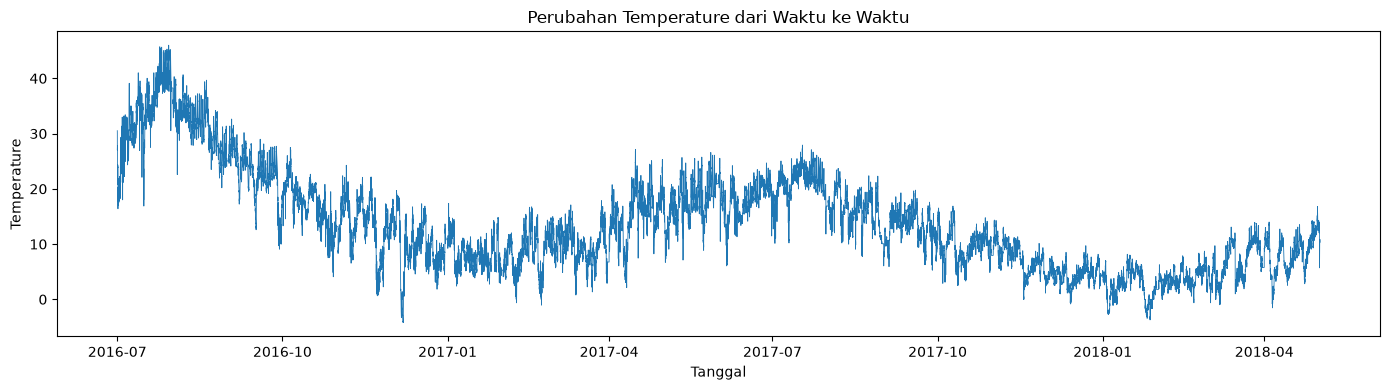

In [6]:
display(train[["Temperature"]].describe())

plt.figure(figsize=(14, 4))
plt.plot(train["date"], train["Temperature"], linewidth=0.6)
plt.title("Perubahan Temperature dari Waktu ke Waktu")
plt.xlabel("Tanggal")
plt.ylabel("Temperature")
plt.tight_layout()
plt.show()

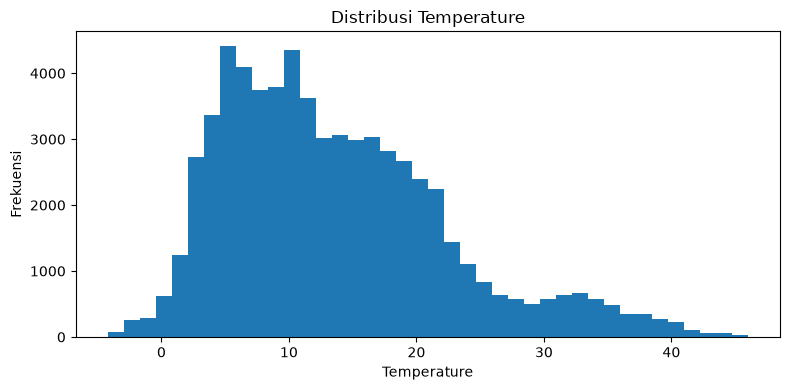

In [7]:
plt.figure(figsize=(8, 4))
plt.hist(train["Temperature"].dropna(), bins=40)
plt.title("Distribusi Temperature")
plt.xlabel("Temperature")
plt.ylabel("Frekuensi")
plt.tight_layout()
plt.show()

,feature_AA,feature_AB,feature_BA,feature_BB,feature_CA,feature_CB,Temperature
feature_AA,1.000000,0.119506,0.986868,0.061591,0.290872,0.040617,0.064954
feature_AB,0.119506,1.000000,0.078182,0.929007,0.231256,0.344268,0.262743
feature_BA,0.986868,0.078182,1.000000,0.046250,0.177148,-0.026984,0.051940
feature_BB,0.061591,0.929007,0.046250,1.000000,0.102385,0.027066,0.247977
feature_CA,0.290872,0.231256,0.177148,0.102385,1.000000,0.313189,0.141227
feature_CB,0.040617,0.344268,-0.026984,0.027066,0.313189,1.000000,0.097044
Temperature,0.064954,0.262743,0.051940,0.247977,0.141227,0.097044,1.000000


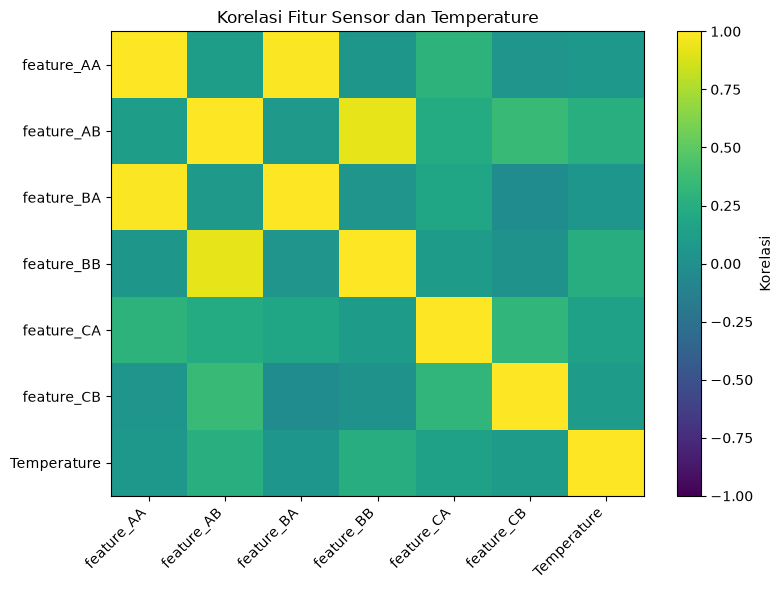

In [8]:
sensor_cols = ["feature_AA", "feature_AB", "feature_BA",
               "feature_BB", "feature_CA", "feature_CB"]

display(train[sensor_cols + ["Temperature"]].corr(numeric_only=True))

corr = train[sensor_cols + ["Temperature"]].corr(numeric_only=True)
plt.figure(figsize=(8, 6))
plt.imshow(corr, vmin=-1, vmax=1, aspect="auto")
plt.colorbar(label="Korelasi")
plt.xticks(range(len(corr.columns)), corr.columns, rotation=45, ha="right")
plt.yticks(range(len(corr.columns)), corr.columns)
plt.title("Korelasi Fitur Sensor dan Temperature")
plt.tight_layout()
plt.show()

## 6. Pemeriksaan outlier dengan IQR

menghitung Q1, Q3, dan IQR serta visualisasikan box plot. Pada tahap ini kita **mendeteksi dan mencatat outlier, bukan langsung menghapusnya**, agar urutan waktu dan data sensor tetap terjaga.

In [9]:
numeric_features = train.select_dtypes(include=np.number).columns.tolist()
numeric_features = [col for col in numeric_features if col not in ["id", "Temperature"]]

Q1 = train[numeric_features].quantile(0.25)
Q3 = train[numeric_features].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outlier_counts = ((train[numeric_features] < lower_bound) |
                  (train[numeric_features] > upper_bound)).sum()

display(outlier_counts.rename("Jumlah outlier per fitur").to_frame())

,Jumlah outlier per fitur
feature_AA,6713
feature_AB,249
feature_BA,7547
feature_BB,320
feature_CA,2159
feature_CB,6998


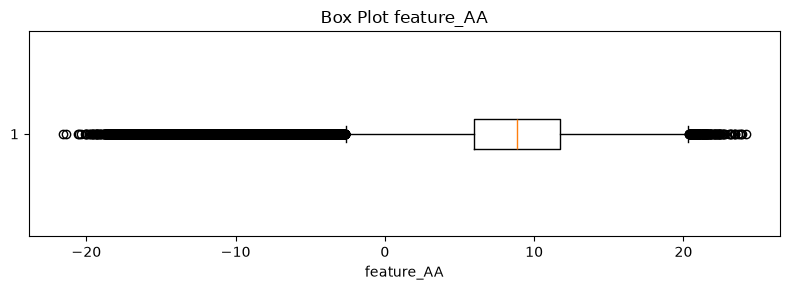

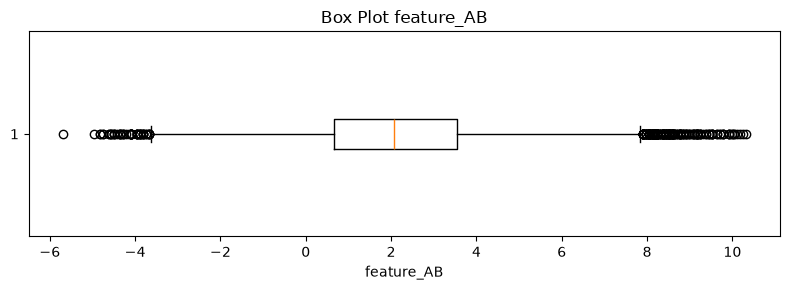

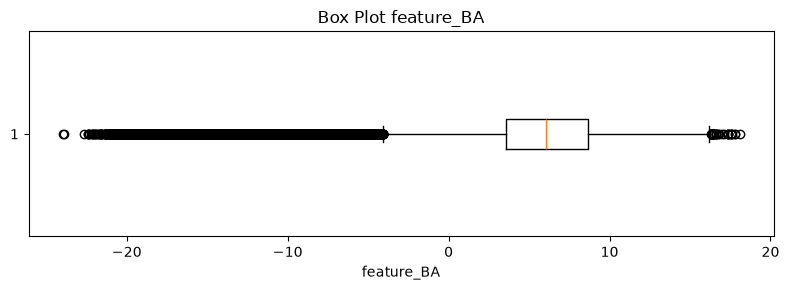

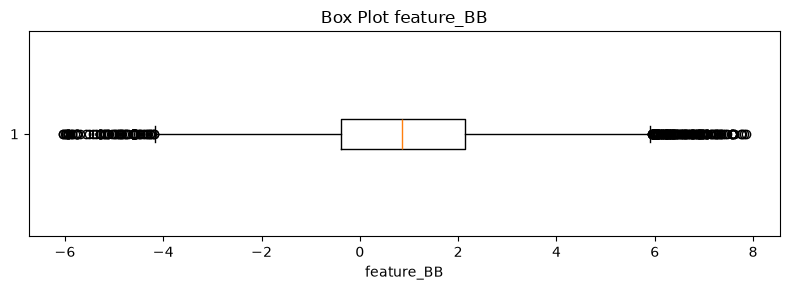

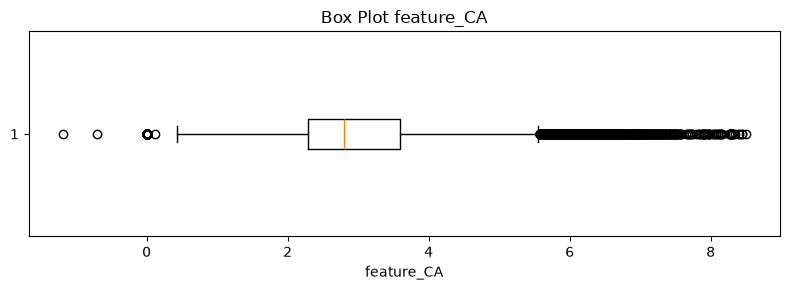

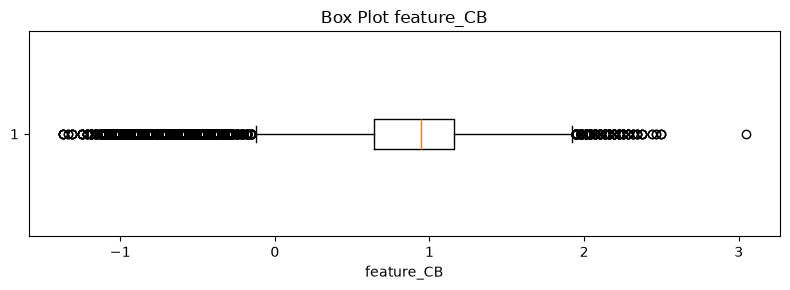

In [10]:
for feature in numeric_features:
    plt.figure(figsize=(8, 3))
    plt.boxplot(train[feature].dropna(), vert=False)
    plt.title(f"Box Plot {feature}")
    plt.xlabel(feature)
    plt.tight_layout()
    plt.show()

## 7. Feature engineering dan preprocessing

Kolom tanggal diubah menjadi fitur waktu. Missing value fitur numerik diisi dengan median yang dihitung dari data training saja. `id` tidak dipakai sebagai fitur prediksi. Target `Temperature` hanya menjadi label (`y`), bukan bagian dari `X`.

In [11]:
def make_features(data):
    result = data.copy()
    dt = pd.to_datetime(result["date"], errors="coerce")
    result["year"] = dt.dt.year
    result["month"] = dt.dt.month
    result["day"] = dt.dt.day
    result["dayofweek"] = dt.dt.dayofweek
    result["hour"] = dt.dt.hour
    result["minute"] = dt.dt.minute
    result["dayofyear"] = dt.dt.dayofyear
    result["hour_sin"] = np.sin(2 * np.pi * result["hour"] / 24)
    result["hour_cos"] = np.cos(2 * np.pi * result["hour"] / 24)
    result["dayofyear_sin"] = np.sin(2 * np.pi * result["dayofyear"] / 365.25)
    result["dayofyear_cos"] = np.cos(2 * np.pi * result["dayofyear"] / 365.25)
    return result

train_fe = make_features(train)
test_fe = make_features(test)

feature_cols = sensor_cols + [
    "year", "month", "day", "dayofweek", "hour", "minute",
    "dayofyear", "hour_sin", "hour_cos", "dayofyear_sin", "dayofyear_cos"
]

for col in feature_cols:
    train_fe[col] = pd.to_numeric(train_fe[col], errors="coerce")
    test_fe[col] = pd.to_numeric(test_fe[col], errors="coerce")

# Median dihitung dari data train agar tidak terjadi data leakage dari test
medians = train_fe[feature_cols].median()
X_all = train_fe[feature_cols].fillna(medians)
X_test = test_fe[feature_cols].fillna(medians)
y_all = train_fe["Temperature"].astype(float)

print("Jumlah fitur:", len(feature_cols))
print("Missing value X train:", int(X_all.isnull().sum().sum()))
print("Missing value X test:", int(X_test.isnull().sum().sum()))
display(X_all.head())

Jumlah fitur: 17
Missing value X train: 0
Missing value X test: 0


,feature_AA,feature_AB,feature_BA,feature_BB,feature_CA,feature_CB,year,month,day,dayofweek,hour,minute,dayofyear,hour_sin,hour_cos,dayofyear_sin,dayofyear_cos
0,5.827,2.009,1.599,0.462,4.203,1.340,2016,7,1,4,0,0,183,0.000000,1.000000,-0.006451,-0.999979
1,5.760,2.076,1.492,0.426,4.264,1.401,2016,7,1,4,0,15,183,0.000000,1.000000,-0.006451,-0.999979
2,5.760,1.942,1.492,0.391,4.234,1.310,2016,7,1,4,0,30,183,0.000000,1.000000,-0.006451,-0.999979
3,5.760,1.942,1.492,0.426,4.234,1.310,2016,7,1,4,0,45,183,0.000000,1.000000,-0.006451,-0.999979
4,5.693,2.076,1.492,0.426,4.142,1.371,2016,7,1,4,1,0,183,0.258819,0.965926,-0.006451,-0.999979


## 8. Data splitting untuk validasi

Karena data memiliki kolom waktu dengan interval berkala, pembagian dilakukan secara kronologis: 80% data awal untuk training dan 20% data terakhir untuk validation. Ini lebih sesuai untuk forecasting dibanding mengacak data secara acak.

In [12]:
order = np.argsort(train_fe["date"].values)
X_ordered = X_all.iloc[order].reset_index(drop=True)
y_ordered = y_all.iloc[order].reset_index(drop=True)

split_idx = int(len(X_ordered) * 0.8)
X_train, X_valid = X_ordered.iloc[:split_idx], X_ordered.iloc[split_idx:]
y_train, y_valid = y_ordered.iloc[:split_idx], y_ordered.iloc[split_idx:]

print("X_train:", X_train.shape)
print("X_valid:", X_valid.shape)
print("Periode validation:",
      train_fe.iloc[order[split_idx]]["date"], "sampai",
      train_fe.iloc[order[-1]]["date"])

X_train: (51456, 17)
X_valid: (12864, 17)
Periode validation: 2017-12-19 00:00:00 sampai 2018-05-01 23:45:00


## 9. Modelling baseline — Quantile Regression

Template `sample_submission.csv` meminta beberapa kuantil. Kita gunakan `HistGradientBoostingRegressor` dengan `loss="quantile"`. Pertama, model median (kuantil 0.50) dievaluasi pada validation set menggunakan MAE, RMSE, dan R².

In [13]:
model_median = HistGradientBoostingRegressor(
    loss="quantile",
    quantile=0.50,
    max_iter=200,
    learning_rate=0.08,
    max_leaf_nodes=31,
    l2_regularization=1.0,
    random_state=42
)

model_median.fit(X_train, y_train)
valid_pred = model_median.predict(X_valid)

mae = mean_absolute_error(y_valid, valid_pred)
rmse = np.sqrt(mean_squared_error(y_valid, valid_pred))
r2 = r2_score(y_valid, valid_pred)

print(f"MAE validation : {mae:.4f}")
print(f"RMSE validation: {rmse:.4f}")
print(f"R² validation  : {r2:.4f}")

MAE validation : 4.9583
RMSE validation: 5.9735
R² validation  : -1.9514


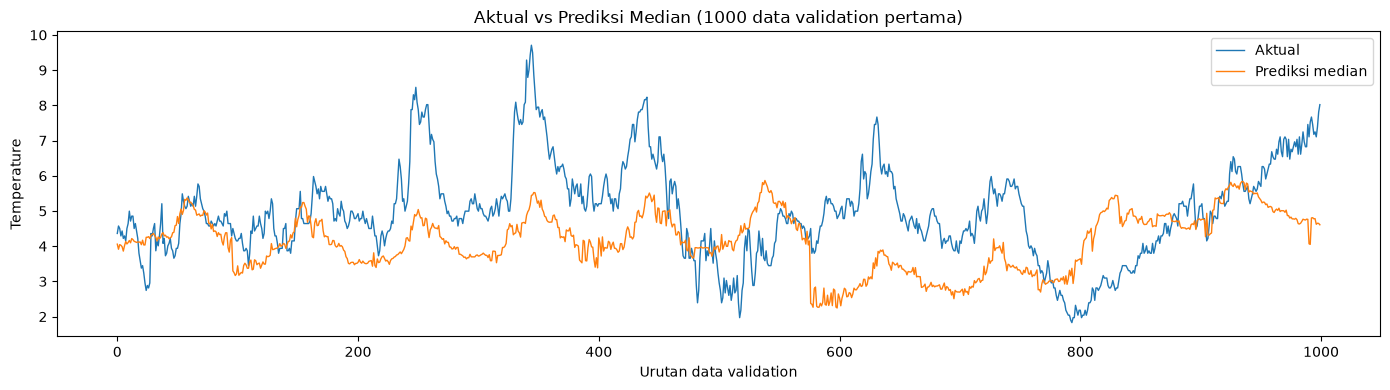

In [14]:
n_plot = min(1000, len(y_valid))
plt.figure(figsize=(14, 4))
plt.plot(y_valid.iloc[:n_plot].to_numpy(), label="Aktual", linewidth=1)
plt.plot(valid_pred[:n_plot], label="Prediksi median", linewidth=1)
plt.title(f"Aktual vs Prediksi Median ({n_plot} data validation pertama)")
plt.xlabel("Urutan data validation")
plt.ylabel("Temperature")
plt.legend()
plt.tight_layout()
plt.show()

## 10. Evaluasi dengan Pinball Loss

Pinball loss sesuai untuk mengevaluasi prediksi kuantil. Semakin kecil nilainya, semakin baik prediksi kuantil pada data validation.

In [15]:
def pinball_loss(y_true, y_pred, q):
    error = np.asarray(y_true) - np.asarray(y_pred)
    return np.mean(np.maximum(q * error, (q - 1) * error))

quantiles_check = [0.10, 0.25, 0.50, 0.75, 0.90]
results = []

for q in quantiles_check:
    model = HistGradientBoostingRegressor(
        loss="quantile", quantile=q,
        max_iter=200, learning_rate=0.08,
        max_leaf_nodes=31, l2_regularization=1.0,
        random_state=42
    )
    model.fit(X_train, y_train)
    pred = model.predict(X_valid)
    results.append({
        "quantile": q,
        "pinball_loss": pinball_loss(y_valid, pred, q)
    })

display(pd.DataFrame(results))

,quantile,pinball_loss
0,0.10,2.659344
1,0.25,3.020056
2,0.50,2.479126
3,0.75,1.505517
4,0.90,0.725567


## 11. Training model final dan prediksi data test

Setelah evaluasi validation, model setiap kuantil dilatih ulang menggunakan seluruh data `train.csv`. Kolom kuantil dibaca langsung dari `sample_submission.csv` supaya sesuai dengan format yang diminta.

In [16]:
quantile_cols = [col for col in sample_submission.columns if col != "id"]
quantiles = [float(col) for col in quantile_cols]

print("Jumlah kuantil:", len(quantiles))
print("Daftar kuantil:", quantiles)

final_order = np.argsort(train_fe["date"].values)
X_final = X_all.iloc[final_order]
y_final = y_all.iloc[final_order]

predictions = {}
for q, col in zip(quantiles, quantile_cols):
    print(f"Melatih model kuantil {q}...")
    model = HistGradientBoostingRegressor(
        loss="quantile",
        quantile=q,
        max_iter=200,
        learning_rate=0.08,
        max_leaf_nodes=31,
        l2_regularization=1.0,
        random_state=42
    )
    model.fit(X_final, y_final)
    predictions[col] = model.predict(X_test)

submission = pd.DataFrame(predictions)
submission.insert(0, "id", test["id"].values)
submission = submission[sample_submission.columns]

display(submission.head())
print("Ukuran submission:", submission.shape)

Jumlah kuantil: 21
Daftar kuantil: [0.025, 0.05, 0.1, 0.15, 0.2, 0.25, 0.3, 0.35, 0.4, 0.45, 0.5, 0.55, 0.6, 0.65, 0.7, 0.75, 0.8, 0.85, 0.9, 0.95, 0.975]
Melatih model kuantil 0.025...
Melatih model kuantil 0.05...
Melatih model kuantil 0.1...
Melatih model kuantil 0.15...
Melatih model kuantil 0.2...
Melatih model kuantil 0.25...
Melatih model kuantil 0.3...
Melatih model kuantil 0.35...
Melatih model kuantil 0.4...
Melatih model kuantil 0.45...
Melatih model kuantil 0.5...
Melatih model kuantil 0.55...
Melatih model kuantil 0.6...
Melatih model kuantil 0.65...
Melatih model kuantil 0.7...
Melatih model kuantil 0.75...
Melatih model kuantil 0.8...
Melatih model kuantil 0.85...
Melatih model kuantil 0.9...
Melatih model kuantil 0.95...
Melatih model kuantil 0.975...


,id,0.025,0.05,0.10,0.15,0.20,0.25,0.30,0.35,0.40,...,0.55,0.60,0.65,0.70,0.75,0.80,0.85,0.90,0.95,0.975
0,64320,6.299466,6.407703,8.186770,8.536603,8.306988,8.928429,9.652596,10.651395,10.507426,...,12.136393,12.130546,11.456241,11.984122,12.372206,11.874359,12.642876,12.997318,13.320389,13.520304
1,64321,6.048363,6.076905,7.905447,8.122958,8.243551,8.941912,9.588434,10.636873,10.429410,...,11.914978,11.842648,11.466816,11.964793,12.221831,11.848286,12.655678,12.895538,13.319553,13.573897
2,64322,6.048363,6.023028,7.881409,8.091045,8.240763,8.941912,9.646390,10.642051,10.458815,...,11.937477,11.919367,11.466816,11.964793,12.372206,11.874359,12.655678,12.945484,13.297002,13.597552
3,64323,5.989681,6.549539,8.407978,8.695394,8.303517,8.944246,9.656860,10.748935,10.596257,...,12.262405,12.102969,11.715953,12.323700,12.741094,12.394047,12.726144,12.997318,13.317577,13.631688
4,64324,5.917872,6.073832,7.893205,8.118875,8.073549,8.296362,9.636388,10.636849,10.474737,...,11.966181,11.982084,11.485676,11.779756,12.292490,11.929382,12.448989,12.772913,13.287490,13.479976


Ukuran submission: (5360, 22)


## 12. Pemeriksaan dan penyimpanan submission

Periksa kesesuaian jumlah baris dan nama kolom dengan template. Untuk menghindari kuantil yang saling silang, nilai prediksi diurutkan per baris dari kuantil terkecil ke terbesar sebelum disimpan.

In [17]:
print("Jumlah baris sesuai template:", len(submission) == len(sample_submission))
print("Kolom sesuai template:", submission.columns.tolist() == sample_submission.columns.tolist())
print("Missing value sebelum pemeriksaan:", int(submission.isnull().sum().sum()))

qcols_sorted = sorted(quantile_cols, key=float)
submission[qcols_sorted] = np.sort(submission[qcols_sorted].to_numpy(), axis=1)

submission.to_csv("submission.csv", index=False)
print("Berhasil menyimpan submission.csv")
display(submission.head())

Jumlah baris sesuai template: True
Kolom sesuai template: True
Missing value sebelum pemeriksaan: 0
Berhasil menyimpan submission.csv


,id,0.025,0.05,0.10,0.15,0.20,0.25,0.30,0.35,0.40,...,0.55,0.60,0.65,0.70,0.75,0.80,0.85,0.90,0.95,0.975
0,64320,6.299466,6.407703,8.186770,8.306988,8.536603,8.928429,9.652596,10.507426,10.651395,...,11.456241,11.874359,11.984122,12.130546,12.136393,12.372206,12.642876,12.997318,13.320389,13.520304
1,64321,6.048363,6.076905,7.905447,8.122958,8.243551,8.941912,9.588434,10.429410,10.636873,...,11.466816,11.842648,11.848286,11.914978,11.964793,12.221831,12.655678,12.895538,13.319553,13.573897
2,64322,6.023028,6.048363,7.881409,8.091045,8.240763,8.941912,9.646390,10.458815,10.642051,...,11.466816,11.874359,11.919367,11.937477,11.964793,12.372206,12.655678,12.945484,13.297002,13.597552
3,64323,5.989681,6.549539,8.303517,8.407978,8.695394,8.944246,9.656860,10.596257,10.748935,...,11.715953,12.102969,12.262405,12.323700,12.394047,12.726144,12.741094,12.997318,13.317577,13.631688
4,64324,5.917872,6.073832,7.893205,8.073549,8.118875,8.296362,9.636388,10.474737,10.636849,...,11.485676,11.779756,11.929382,11.966181,11.982084,12.292490,12.448989,12.772913,13.287490,13.479976


## 13. Kesimpulan

Notebook ini melakukan data loading, pemeriksaan missing value dan duplikasi, EDA, deteksi outlier menggunakan IQR, feature engineering, pembagian data berdasarkan waktu, modelling quantile regression, evaluasi, dan pembuatan submission.